In [ ]:
from google.colab import files
uploaded = files.upload()

Saving superstore_sales.csv to superstore_sales.csv


In [ ]:
import pandas as pd

df = pd.read_csv("superstore_sales.csv")

df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164


In [ ]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (10800, 21)

Column Names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Missing Values:
Row ID             0
Order ID           0
Order Date       806
Ship Date        806
Ship Mode        806
Customer ID      806
Customer Name    806
Segment          806
Country          806
City             806
State            806
Postal Code      817
Region           806
Product ID       806
Category         806
Sub-Category     806
Product Name     806
Sales            806
Quantity         806
Discount         806
Profit           806
dtype: int64


In [ ]:
# Check rows where Order Date is missing
missing_rows = df[df["Order Date"].isna()]

print("Missing date rows:", len(missing_rows))
print("\nSample of missing rows:")
display(missing_rows.head(10))

Missing date rows: 806

Sample of missing rows:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
9994,Person,Region,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9995,Anna Andreadi,West,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9996,Chuck Magee,East,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9997,Kelly Williams,Central,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9998,Cassandra Brandow,South,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9999,Returned,Order ID,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10000,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10001,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10002,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10003,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# Keep only rows with a valid Order Date
df_clean = df[df["Order Date"].notna()].copy()

print("Original rows:", len(df))
print("Cleaned rows:", len(df_clean))
print("Missing values after cleaning:")
print(df_clean.isnull().sum())

Original rows: 10800
Cleaned rows: 9994
Missing values after cleaning:
Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country           0
City              0
State             0
Postal Code      11
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
Quantity          0
Discount          0
Profit            0
dtype: int64


In [ ]:
df_clean["Order Date"] = pd.to_datetime(
    df_clean["Order Date"], errors="coerce"
)

df_clean["Ship Date"] = pd.to_datetime(
    df_clean["Ship Date"], errors="coerce"
)

print(df_clean[["Order Date", "Ship Date"]].head())

print("\nDate data types:")
print(df_clean[["Order Date", "Ship Date"]].dtypes)

  Order Date  Ship Date
0 2017-11-08 2017-11-11
1 2017-11-08 2017-11-11
2 2017-06-12 2017-06-16
3 2016-10-11 2016-10-18
4 2016-10-11 2016-10-18

Date data types:
Order Date    datetime64[ns]
Ship Date     datetime64[ns]
dtype: object


In [ ]:
df_clean["Year-Month"] = df_clean["Order Date"].dt.to_period("M")

monthly_sales = df_clean.groupby("Year-Month")["Sales"].sum()

print(monthly_sales)

Year-Month
2015-01     14236.8950
2015-02      4519.8920
2015-03     55691.0090
2015-04     28295.3450
2015-05     23648.2870
2015-06     34595.1276
2015-07     33946.3930
2015-08     27909.4685
2015-09     81777.3508
2015-10     31453.3930
2015-11     78628.7167
2015-12     69545.6205
2016-01     18174.0756
2016-02     11951.4110
2016-03     38726.2520
2016-04     34195.2085
2016-05     30131.6865
2016-06     24797.2920
2016-07     28765.3250
2016-08     36898.3322
2016-09     64595.9180
2016-10     31404.9235
2016-11     75972.5635
2016-12     74919.5212
2017-01     18542.4910
2017-02     22978.8150
2017-03     51715.8750
2017-04     38750.0390
2017-05     56987.7280
2017-06     40344.5340
2017-07     39261.9630
2017-08     31115.3743
2017-09     73410.0249
2017-10     59687.7450
2017-11     79411.9658
2017-12     96999.0430
2018-01     43971.3740
2018-02     20301.1334
2018-03     58872.3528
2018-04     36521.5361
2018-05     44261.1102
2018-06     52981.7257
2018-07     45264.4160


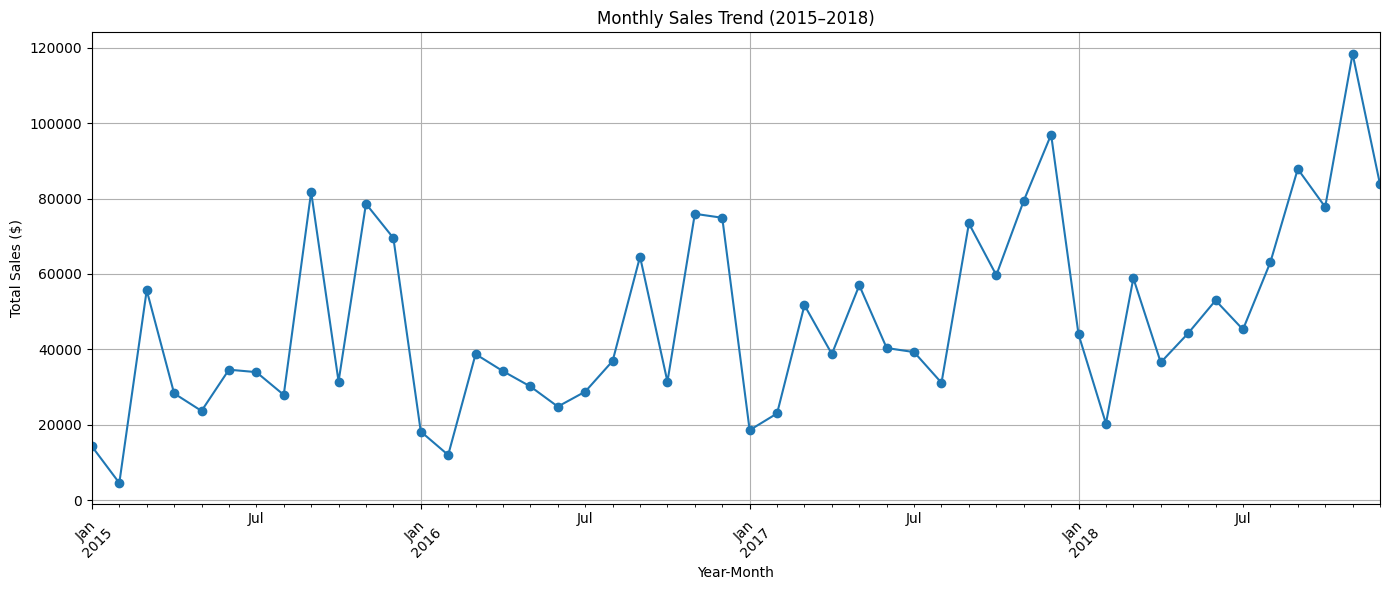

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

monthly_sales.plot(kind="line", marker="o")

plt.title("Monthly Sales Trend (2015–2018)")
plt.xlabel("Year-Month")
plt.ylabel("Total Sales ($)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.show()

In [ ]:
category_analysis = df_clean.groupby("Category").agg({
    "Sales": "sum",
    "Profit": "sum",
    "Quantity": "sum"
}).round(2)

print(category_analysis)

                     Sales     Profit  Quantity
Category                                       
Furniture        741999.80   18451.27    8028.0
Office Supplies  719047.03  122490.80   22906.0
Technology       836154.03  145454.95    6939.0


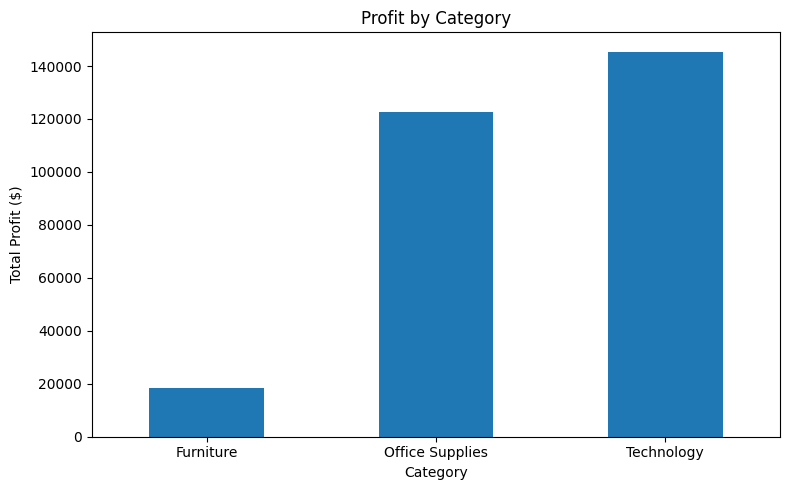

In [ ]:
category_analysis["Profit"].plot(
    kind="bar",
    figsize=(8, 5),
    title="Profit by Category",
    ylabel="Total Profit ($)",
    xlabel="Category",
    rot=0
)

plt.tight_layout()
plt.show()

In [ ]:
region_analysis = df_clean.groupby("Region").agg({
    "Sales": "sum",
    "Profit": "sum",
    "Quantity": "sum"
}).round(2)

print(region_analysis)

             Sales     Profit  Quantity
Region                                 
Central  501239.89   39706.36    8780.0
East     678781.24   91522.78   10618.0
South    391721.90   46749.43    6209.0
West     725457.82  108418.45   12266.0


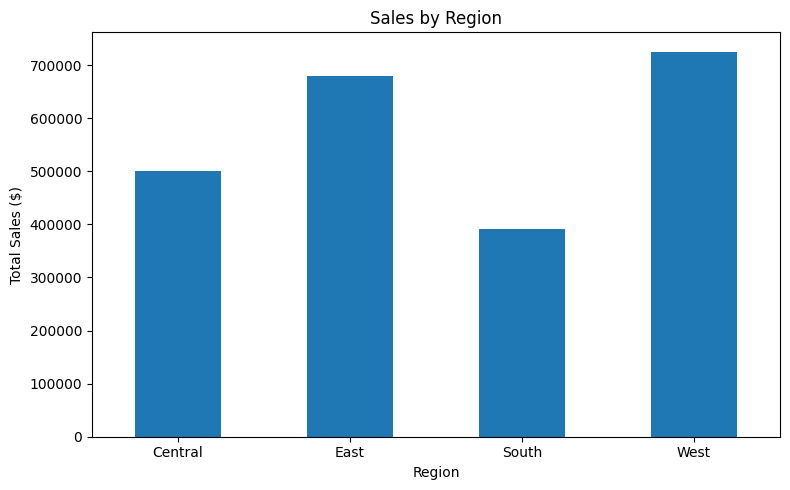

In [ ]:
region_analysis["Sales"].plot(
    kind="bar",
    figsize=(8, 5),
    title="Sales by Region",
    ylabel="Total Sales ($)",
    xlabel="Region",
    rot=0
)

plt.tight_layout()
plt.show()

In [ ]:
discount_analysis = df_clean.groupby("Discount").agg({
    "Sales": "sum",
    "Profit": "mean"
}).round(2)

print(discount_analysis)

               Sales  Profit
Discount                    
0.00      1087908.47   66.90
0.10        54369.35   96.06
0.15        27558.52   27.29
0.20       764594.37   24.70
0.30       103226.66  -45.68
0.32        14493.46  -88.56
0.40       116417.78 -111.93
0.45         5484.97 -226.65
0.50        58918.54 -310.70
0.60         6644.70  -43.08
0.70        40620.28  -95.87
0.80        16963.76 -101.80


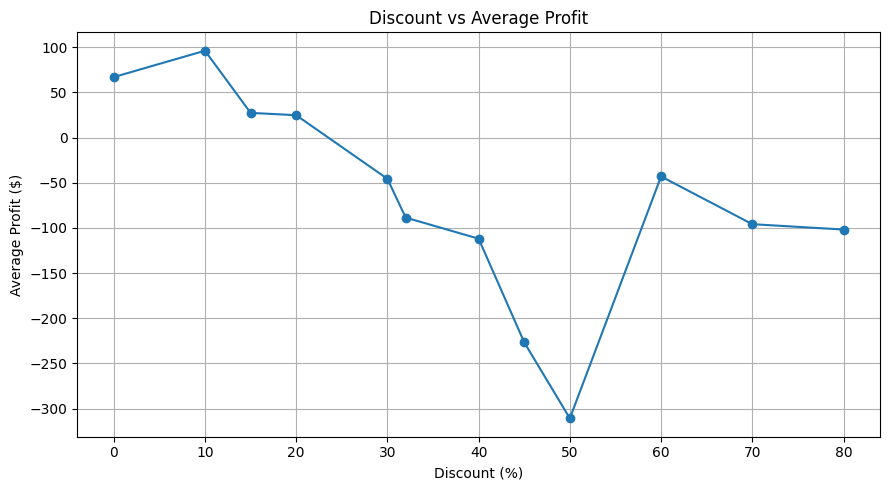

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(
    discount_analysis.index * 100,
    discount_analysis["Profit"],
    marker="o"
)

plt.title("Discount vs Average Profit")
plt.xlabel("Discount (%)")
plt.ylabel("Average Profit ($)")
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
segment_analysis = df_clean.groupby("Segment").agg({
    "Sales": "sum",
    "Profit": "sum",
    "Quantity": "sum",
    "Customer ID": "nunique"
}).round(2)

print(segment_analysis)

                  Sales     Profit  Quantity  Customer ID
Segment                                                  
Consumer     1161401.34  134119.21   19521.0          409
Corporate     706146.37   91979.13   11608.0          236
Home Office   429653.15   60298.68    6744.0          148


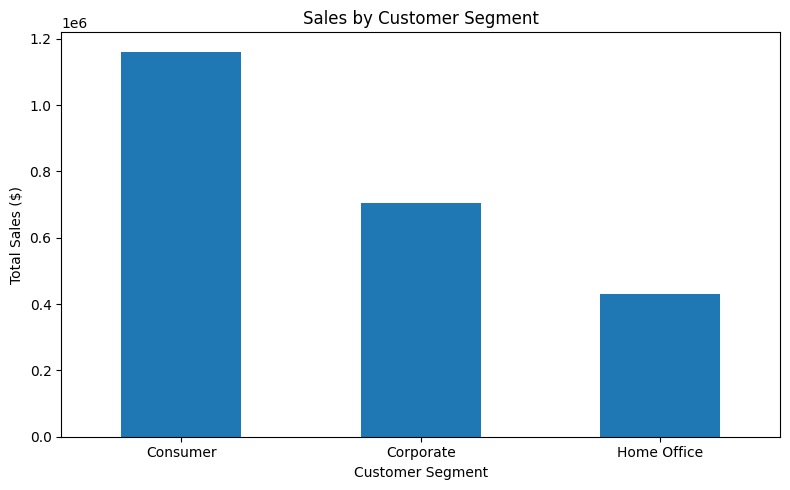

In [ ]:
segment_analysis["Sales"].plot(
    kind="bar",
    figsize=(8, 5),
    title="Sales by Customer Segment",
    ylabel="Total Sales ($)",
    xlabel="Customer Segment",
    rot=0
)

plt.tight_layout()
plt.show()

Monthly Sales: November 2018 recorded the highest monthly sales of $118,447.83.



Category Performance: Technology generated the highest sales ($836,154.03) and profit ($145,454.95).



Furniture Profit: Furniture generated only $18,451.27 profit despite $741,999.80 sales.



Regional Performance: West region achieved the highest sales ($725,457.82) and profit ($108,418.45).



Discount Impact: Higher discounts, especially 45% and 50%, were associated with negative average profit.



Customer Segment: Consumer segment generated the highest sales ($1,161,401.34) and profit ($134,119.21).



Customer Base: Consumer had 409 unique customers, Corporate 236, and Home Office 148.


In [ ]:
insights = """
# Superstore Sales Analysis – Executive Insights

1. November 2018 recorded the highest monthly sales of $118,447.83.

2. Technology generated the highest sales of $836,154.03
   and profit of $145,454.95.

3. Furniture generated only $18,451.27 profit despite
   sales of $741,999.80.

4. West region achieved the highest sales of $725,457.82
   and profit of $108,418.45.

5. Higher discount levels were associated with negative
   average profit, especially at 45% and 50% discounts.

6. Consumer segment generated the highest sales of
   $1,161,401.34 and profit of $134,119.21.

7. Consumer segment had 409 unique customers, followed
   by Corporate with 236 and Home Office with 148.
"""

with open("insights.md", "w") as file:
    file.write(insights)

print("Executive insights saved successfully!")

Executive insights saved successfully!
